# Example of the aitlas toolbox in the context of semantic segmentation

## Import the required packages

In [ ]:
from aitlas.datasets import SEN12MSDataset
from aitlas.utils import image_loader
from aitlas.models import DeepLabV3
from aitlas.transforms import MinMaxNormTranspose
import matplotlib.pyplot as plt
import csv

## Visualize images and masks

Total number of patches: 144348


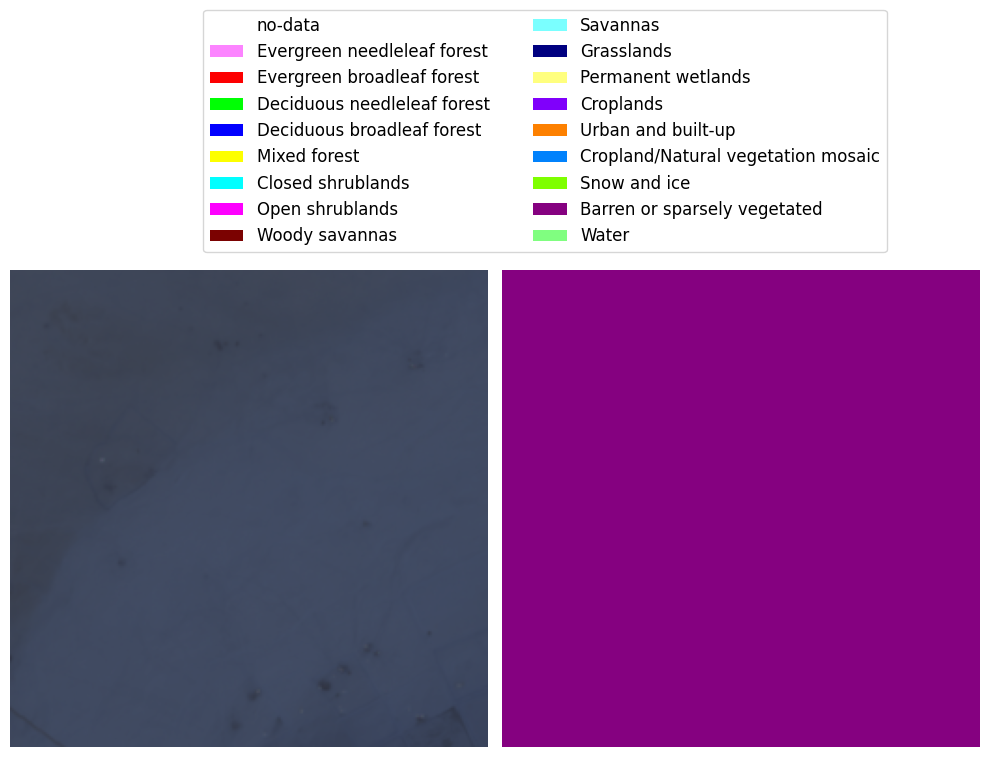

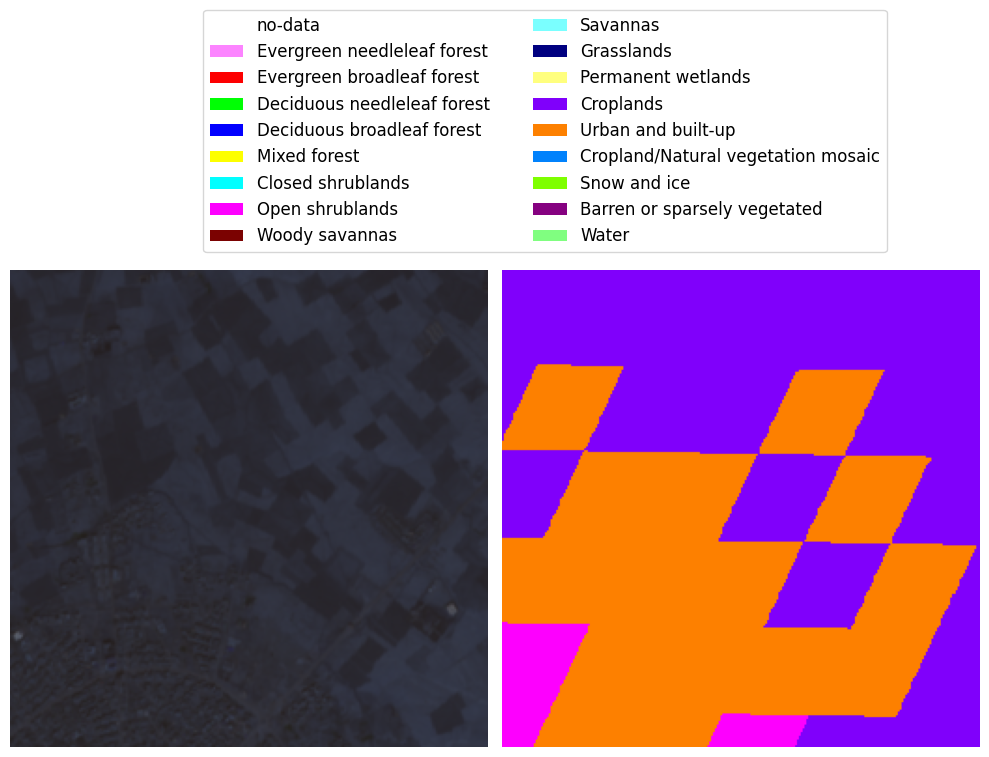

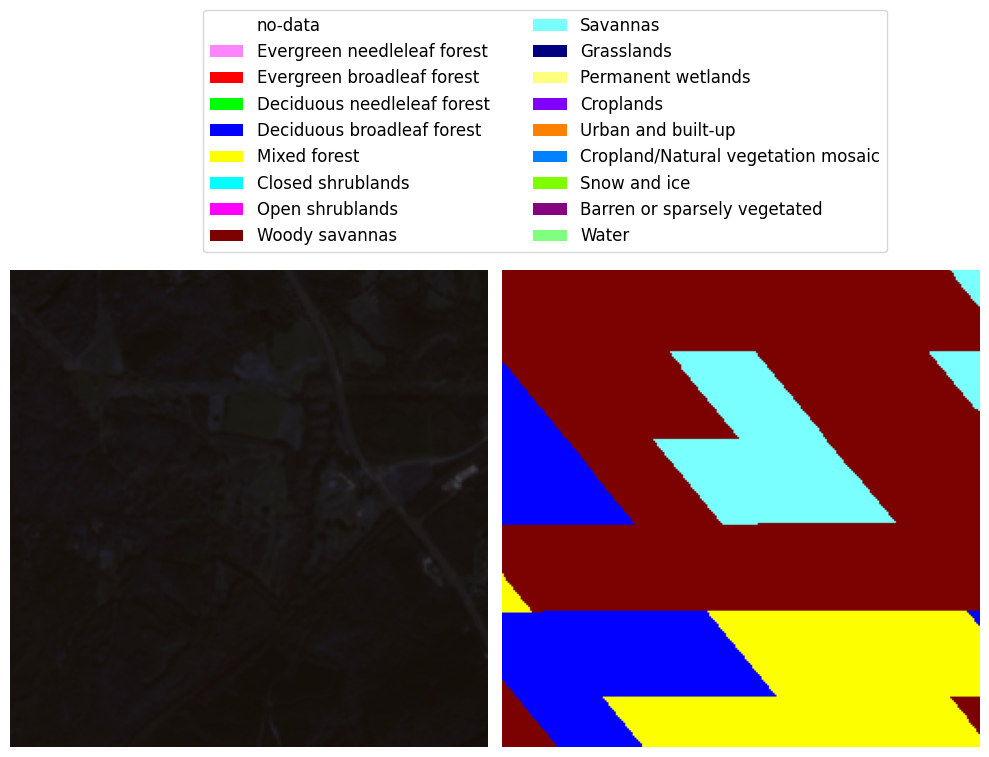

In [56]:
dataset_config = {
    "data_dir": "/home/dragik/data/FAIR_EO/SEN12MS/images/s2",
    "csv_file": "/home/dragik/data/FAIR_EO/SEN12MS/train.csv",
}
dataset = SEN12MSDataset(dataset_config)

print(f"Total number of patches: {len(dataset)}")
dataset.show_image(1);
dataset.show_image(350);
dataset.show_image(1500);

In [57]:
dataset.data_distribution_table()

,Number of pixels
no-data,0.000000e+00
Evergreen needleleaf forest,2.016965e+08
Evergreen broadleaf forest,1.999466e+08
Deciduous needleleaf forest,3.000806e+06
Deciduous broadleaf forest,3.810724e+08
Mixed forest,2.829044e+08
Closed shrublands,2.250889e+07
Open shrublands,6.285715e+08
Woody savannas,7.426422e+08
Savannas,1.499632e+09


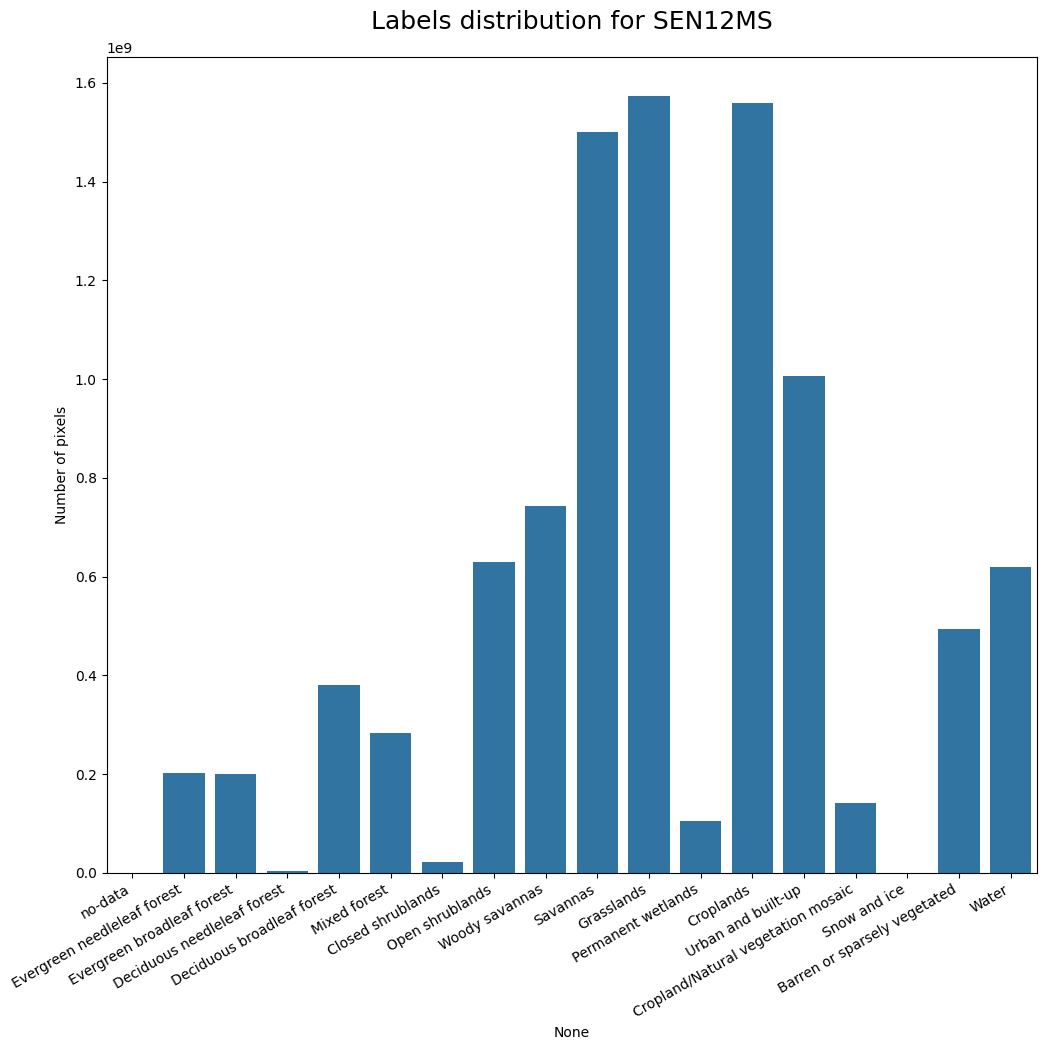

In [58]:
dataset.data_distribution_barchart();

## Load training data

In [4]:
train_dataset_config = {
    "batch_size": 8,
    "shuffle": True,
    "num_workers": 4,
    "data_dir": "/home/dragik/data/FAIR_EO/SEN12MS/images/s2",
    "csv_file": "/home/dragik/data/FAIR_EO/SEN12MS/train.csv",
    "transforms": ["aitlas.transforms.MinMaxNormTranspose","aitlas.transforms.ResizeToTensor"], 
    "target_transforms": ["aitlas.transforms.Transpose","aitlas.transforms.ResizePerChannelToTensor"] 
}
train_dataset = SEN12MSDataset(train_dataset_config)
len(train_dataset)

144348

## Create the model

In [5]:
epochs = 10
model_directory = "/home/dragik/data/FAIR_EO/SEN12MS"
model_config = {
    "num_classes": 18, 
    "learning_rate": 0.0001,
    "pretrained": True, 
    "threshold": 0.5,
    "metrics": ["iou"]
}

model = DeepLabV3(model_config)
model.prepare()

## Start the training

In [6]:
model.train_model(
    train_dataset=train_dataset,
    epochs=epochs,
    model_directory=model_directory,
    run_id='1'
);

2025-06-09 16:11:13,307 INFO Starting training.
training: 100%|██████████| 18044/18044 [29:08<00:00, 10.32it/s]
2025-06-09 16:40:21,962 INFO epoch: 1, time: 1748, loss:  0.75350
testing on train set: 100%|██████████| 18044/18044 [14:01<00:00, 21.45it/s]
2025-06-09 16:54:25,158 INFO IOU:0.13049601228287175, IOU mean:0.032359536344830846, IOU per Class:[0.         0.         0.         0.         0.         0.
 0.         0.         0.         0.15852373 0.15273386 0.
 0.16477508 0.10643898 0.         0.         0.         0.        ]
training: 100%|██████████| 18044/18044 [31:05<00:00,  9.67it/s]
2025-06-09 17:25:30,762 INFO epoch: 2, time: 1865, loss:  0.74745
testing on train set: 100%|██████████| 18044/18044 [14:07<00:00, 21.29it/s]
2025-06-09 17:39:38,270 INFO IOU:0.12036589312638649, IOU mean:0.02387432214280261, IOU per Class:[0.         0.         0.         0.         0.         0.
 0.         0.         0.         0.15852373 0.         0.
 0.16477508 0.10643898 0.         0.   

## Evaluate the model

In [6]:
test_dataset_config = {
    "batch_size": 4,
    "shuffle": False,
    "num_workers": 4,
    "data_dir": "/home/dragik/data/FAIR_EO/SEN12MS/images/s2",
    "csv_file": "/home/dragik/data/FAIR_EO/SEN12MS/val.csv",
    "transforms": ["aitlas.transforms.MinMaxNormTranspose","aitlas.transforms.ResizeToTensor"], 
    "target_transforms": ["aitlas.transforms.Transpose","aitlas.transforms.ResizePerChannelToTensor"] 
}

test_dataset = SEN12MSDataset(test_dataset_config)
print(len(test_dataset))

model = DeepLabV3(model_config)
model.prepare()
model.running_metrics.reset()
model_path = "/home/dragik/data/FAIR_EO/SEN12MS/checkpoint.pth.tar"
model.evaluate(dataset=test_dataset, model_path=model_path)
model.running_metrics.get_scores(model.metrics)

18043


2025-06-10 06:35:52,509 INFO Loading checkpoint /home/dragik/data/FAIR_EO/SEN12MS/checkpoint.pth.tar
2025-06-10 06:35:53,030 INFO Loaded checkpoint /home/dragik/data/FAIR_EO/SEN12MS/checkpoint.pth.tar at epoch 11
testing on test set: 100%|██████████| 4511/4511 [01:48<00:00, 41.44it/s]


[{'IOU': 0.1420039258590093,
  'IOU mean': 0.03253204289912348,
  'IOU per Class': array([0.        , 0.        , 0.        , 0.        , 0.        ,
         0.        , 0.        , 0.02212401, 0.        , 0.15915886,
         0.16932112, 0.        , 0.16236203, 0.07261075, 0.        ,
         0.        , 0.        , 0.        ])}]

## Predictions

2025-06-10 06:41:09,958 INFO Loading checkpoint /home/dragik/data/FAIR_EO/SEN12MS/checkpoint.pth.tar
2025-06-10 06:41:10,368 INFO Loaded checkpoint /home/dragik/data/FAIR_EO/SEN12MS/checkpoint.pth.tar at epoch 11


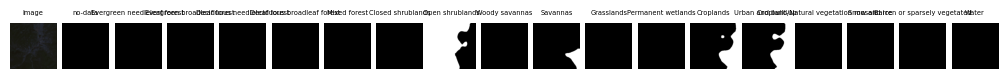

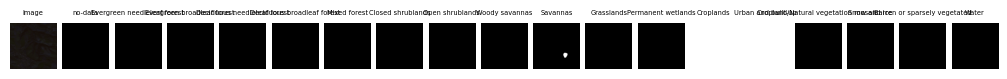

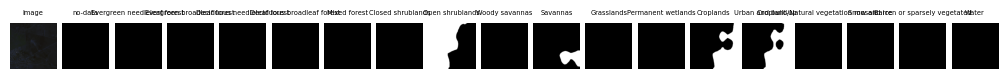

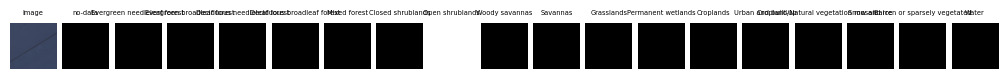

In [10]:
model_path = "/home/dragik/data/FAIR_EO/SEN12MS/checkpoint.pth.tar"
labels = ["no-data","Evergreen needleleaf forest","Evergreen broadleaf forest","Deciduous needleleaf forest",
              "Deciduous broadleaf forest","Mixed forest","Closed shrublands","Open shrublands","Woody savannas",
              "Savannas","Grasslands","Permanent wetlands","Croplands","Urban and built-up","Cropland/Natural vegetation mosaic",
              "Snow and ice","Barren or sparsely vegetated","Water"]
transform = MinMaxNormTranspose()
model.load_model(model_path)
plt.rcParams.update({'font.size': 4})
csv_file = "/home/dragik/data/FAIR_EO/SEN12MS/test.csv"

test_list = []
with open(csv_file, mode ='r')as file:
    csvFile = csv.reader(file)
    for lines in csvFile:
        test_list.append(lines[0])

image = image_loader('/home/dragik/data/FAIR_EO/SEN12MS/images/' + test_list[0])[:,:,1:4]/10000
fig = model.predict_masks(image, labels, transform)

image = image_loader('/home/dragik/data/FAIR_EO/SEN12MS/images/' + test_list[1])[:,:,1:4]/10000
fig = model.predict_masks(image, labels, transform)

image = image_loader('/home/dragik/data/FAIR_EO/SEN12MS/images/' + test_list[10])[:,:,1:4]/10000
fig = model.predict_masks(image, labels, transform)

image = image_loader('/home/dragik/data/FAIR_EO/SEN12MS/images/' + test_list[50])[:,:,1:4]/10000
fig = model.predict_masks(image, labels, transform)